# Analysis of Heston model and Black-Scholes Call Pricing

### Numerical scheme for Heston

In [3]:
#using kahl and jackel paper values:

S = 1
F = 1
r = 0
nu_0 = 0.16
nu_bar = 0.16
lamb = 1
eta = 2
rho = -0.8
tau = 10
K = 2

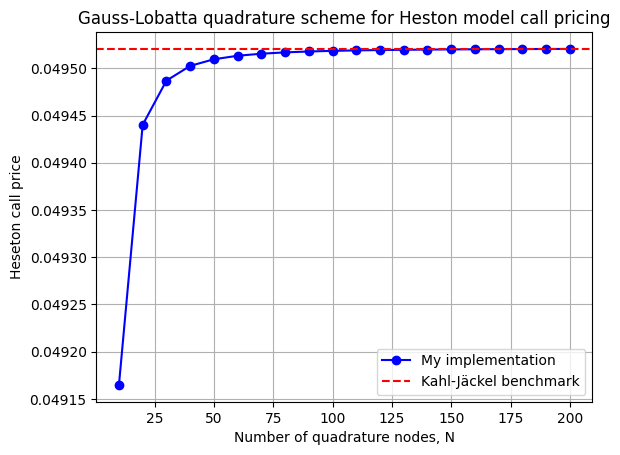

In [11]:
import numpy as np
from heston import heston_price
import matplotlib.pyplot as plt

# Sketch for different Ns:

Ns = np.arange(10, 210, 10)

ys = [heston_price(N, F, K, lamb, nu_bar, eta, tau, nu_0, rho, r) for N in Ns]

plt.plot(Ns, ys, 'o-', color = 'blue', label = "My implementation")
V_KJ = 0.04952051
plt.axhline(V_KJ, color = 'red', linestyle = '--', label = "Kahl-Jäckel benchmark")
plt.xlabel("Number of quadrature nodes, N")
plt.ylabel("Heseton call price")
plt.title("Gauss-Lobatta quadrature scheme for Heston model call pricing")
plt.grid()
plt.legend()
plt.show()





This looks pretty good, next plot the error against N, using the benchmark:

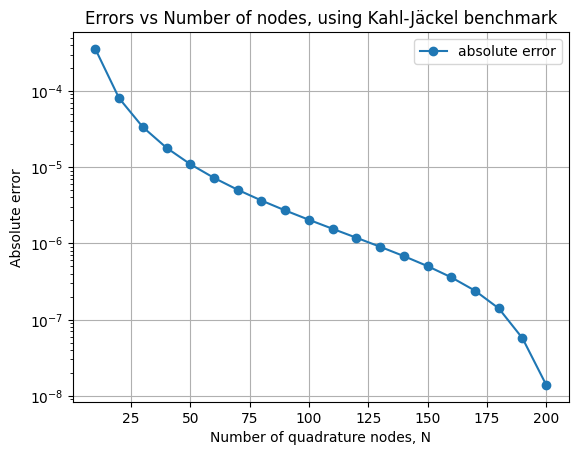

In [16]:
es = [np.abs(y - V_KJ) for y in ys]
plt.semilogy(Ns, es, 'o-', label = "absolute error")
plt.legend()
plt.grid()
plt.xlabel("Number of quadrature nodes, N")
plt.ylabel("Absolute error")
plt.title("Errors vs Number of nodes, using Kahl-Jäckel benchmark")
plt.show()



In [19]:
# ratio of errors:
rs = np.array(es[1:]) / np.array(es[:-1])

for N, ratio in zip(Ns[1:], rs):
    print(f"N = {N}: {ratio:.6f}")


N = 20: 0.225883
N = 30: 0.417973
N = 40: 0.534404
N = 50: 0.609797
N = 60: 0.661175
N = 70: 0.697355
N = 80: 0.723192
N = 90: 0.741482
N = 100: 0.753856
N = 110: 0.761205
N = 120: 0.763870
N = 130: 0.761685
N = 140: 0.753864
N = 150: 0.738668
N = 160: 0.712554
N = 170: 0.667926
N = 180: 0.585987
N = 190: 0.405595
N = 200: 0.244298


## Comparison of Heston vs Black-Scholes against different Strike Prices:

In [ ]:
# First set parameters for comparison:
S = 100
r = 0.05
q = 0
tau = 1 
